# Лабораторная работа №4

**Выполнили:** Трегубович Андрей (M3339, ИСУ 467749), Солоненко Андрей (M3338, ИСУ 467557).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, shapiro, cramervonmises_2samp, spearmanr
from pathlib import Path
from urllib.request import urlopen

SEED = 1337
rng = np.random.default_rng(SEED)

alpha = 0.05
R = 4999

## Данные

Используем датасет [Iris](https://archive.ics.uci.edu/dataset/53/iris) Р. Фишера, который уже рассматривали в первой лабораторной. В нём 150 цветков трёх видов, по 50 каждого вида. Все размеры указаны в сантиметрах.

Есть четыре количественных признака: длина и ширина чашелистика, длина и ширина лепестка. Вид ириса — категориальный признак. Предполагаем, что длина и ширина лепестка связаны, поэтому данные подходят под условия работы.

Если файл `iris.csv` существует, читаем его. Иначе скачиваем `bezdekIris.data` из UCI и сохраняем с названиями столбцов.

Источник: Fisher, R. (1936). Iris. UCI Machine Learning Repository, [DOI](https://doi.org/10.24432/C56C76). Лицензия CC BY 4.0.

In [2]:
if Path('iris.csv').exists():
    print('Используем файл iris.csv')
else:
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/bezdekIris.data'
    text = urlopen(url).read().decode('utf-8')
    header = 'sepal_length,sepal_width,petal_length,petal_width,species\n'
    Path('iris.csv').write_text(header + text, encoding='utf-8')
    print('Датасет скачан')

data = np.genfromtxt('iris.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
sepal_length = data['sepal_length']
sepal_width = data['sepal_width']
petal_length = data['petal_length']
petal_width = data['petal_width']
species = data['species']

print('Объём выборки:', len(data))
for name in np.unique(species):
    print(name, np.sum(species == name))
print('Количество пропусков:', np.isnan(np.column_stack(
    [sepal_length, sepal_width, petal_length, petal_width])).sum())

Используем файл iris.csv
Объём выборки: 150
Iris-setosa 50
Iris-versicolor 50
Iris-virginica 50
Количество пропусков: 0


## Задание 1. Проверка распределения

Выберем ширину чашелистика. Предположим, что она имеет нормальное распределение $N(\mu, \sigma^2)$. Оценим параметры по выборке:

$$\hat\mu = \bar x, \qquad \hat\sigma^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \bar x)^2.$$

Считаем наблюдения независимыми. Во всех заданиях используем уровень значимости $\alpha = 0.05$. Если $p < \alpha$, отклоняем $H_0$, иначе нет оснований её отклонять. Каждую проверку рассматриваем отдельно, без поправки на множественные проверки.

### Эксперимент

Среднее: 3.057, стандартное отклонение: 0.434


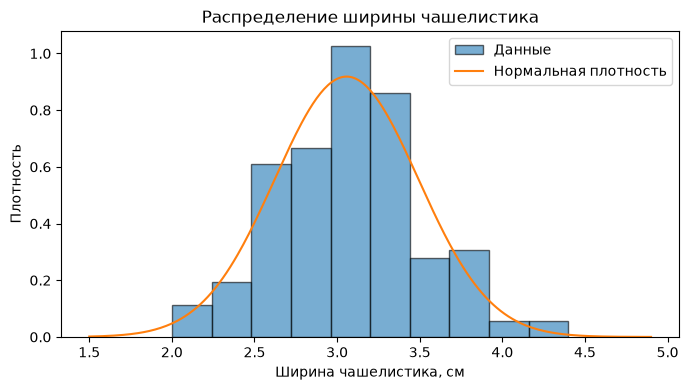

In [3]:
x = sepal_width
mu = x.mean()
sigma = x.std(ddof=0)
print(f'Среднее: {mu:.3f}, стандартное отклонение: {sigma:.3f}')

grid = np.linspace(x.min() - 0.5, x.max() + 0.5, 300)
plt.figure(figsize=(7, 4))
plt.hist(x, bins=10, density=True, alpha=0.6, edgecolor='black', label='Данные')
plt.plot(grid, norm.pdf(grid, mu, sigma), label='Нормальная плотность')
plt.xlabel('Ширина чашелистика, см')
plt.ylabel('Плотность')
plt.title('Распределение ширины чашелистика')
plt.legend()
plt.tight_layout()
plt.show()

### Критерий Шапиро — Уилка

$H_0$: ширина чашелистика имеет нормальное распределение.

$H_1$: распределение ширины чашелистика отличается от нормального.

Используем готовую реализацию из `scipy.stats`.

In [4]:
w, p_shapiro = shapiro(x)
print(f'W = {w:.4f}, p = {p_shapiro:.4f}')
print('Отклоняем H0:', p_shapiro < alpha)

W = 0.9849, p = 0.1012
Отклоняем H0: False


### Критерий Пирсона

$H_0$: ширина чашелистика имеет нормальное распределение с неизвестными параметрами.

$H_1$: распределение ширины чашелистика отличается от нормального.

Реализуем критерий самостоятельно. Разделим числовую прямую на 6 интервалов, вероятность попадания в каждый из которых при выбранном нормальном законе равна $1/6$. Крайние интервалы бесконечные. Ожидаемая частота в каждом интервале равна $E_i = n/6 = 25 > 5$.

Статистика критерия:

$$Q = \sum_{i=1}^6 \frac{(O_i - E_i)^2}{E_i},$$

где $O_i$ — наблюдаемое число значений в интервале.

Параметры и границы интервалов оценены по выборке. Поэтому p-value найдём моделированием: генерируем $R=4999$ нормальных выборок такого же объёма и в каждой заново оцениваем параметры и считаем $Q$. Это параметрический бутстрэп.

Если $b$ статистик не меньше наблюдаемой, берём $p = (b+1)/(R+1)$. Эту же формулу используем в перестановочных тестах ниже.

In [5]:
def pearson_stat(sample, k=6):
    mean = sample.mean()
    std = sample.std(ddof=0)
    edges = norm.ppf(np.linspace(0, 1, k + 1), loc=mean, scale=std)
    observed, _ = np.histogram(sample, bins=edges)
    expected = len(sample) / k
    q = np.sum((observed - expected) ** 2 / expected)
    return q, observed

q, observed = pearson_stat(x)
count = 0
for _ in range(R):
    sample = rng.normal(mu, sigma, size=len(x))
    q_sim, _ = pearson_stat(sample)
    if q_sim >= q:
        count += 1
p_pearson = (count + 1) / (R + 1)

print('Наблюдаемые частоты:', observed)
print('Ожидаемые частоты:', np.full(6, len(x) / 6))
print(f'Q = {q:.4f}, p = {p_pearson:.4f}')
print('Отклоняем H0:', p_pearson < alpha)

Наблюдаемые частоты: [24 23 36 24 18 25]
Ожидаемые частоты: [25. 25. 25. 25. 25. 25.]
Q = 7.0400, p = 0.0966
Отклоняем H0: False


### Вывод

Оба критерия не дают оснований отклонять нормальность при $\alpha = 0.05$. Нормальное распределение можно использовать как приближённую модель ширины чашелистика, но это не доказывает, что распределение в точности нормальное. В данных значения округлены до 0.1 см, тогда как моделируемый нормальный закон непрерывный.

## Задание 2. Проверка однородности

Выберем длину чашелистика и разделим её на две подвыборки по видам: setosa и versicolor. В каждой подвыборке по 50 наблюдений. Сравним распределения с помощью двух критериев, не требующих нормальности.

### Эксперимент

Setosa: n = 50, среднее = 5.006
Versicolor: n = 50, среднее = 5.936


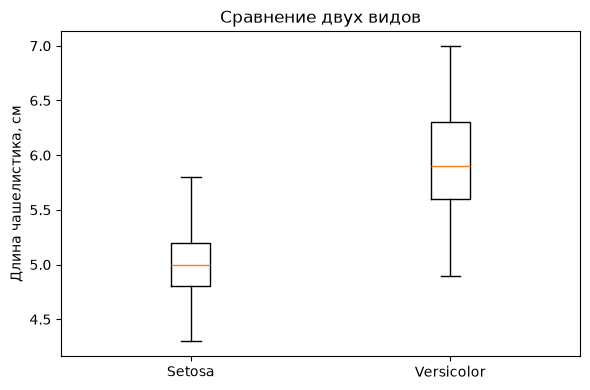

In [6]:
a = sepal_length[species == 'Iris-setosa']
b = sepal_length[species == 'Iris-versicolor']
print(f'Setosa: n = {len(a)}, среднее = {a.mean():.3f}')
print(f'Versicolor: n = {len(b)}, среднее = {b.mean():.3f}')

plt.figure(figsize=(6, 4))
plt.boxplot([a, b], tick_labels=['Setosa', 'Versicolor'])
plt.ylabel('Длина чашелистика, см')
plt.title('Сравнение двух видов')
plt.tight_layout()
plt.show()

### Критерий Колмогорова — Смирнова

$H_0$: распределения длины чашелистика у setosa и versicolor совпадают.

$H_1$: распределения длины чашелистика у этих видов различаются.

Реализуем критерий самостоятельно. Считаем максимальное расстояние между эмпирическими функциями распределения:

$$D = \max_x |F_1(x) - F_2(x)|.$$

Для p-value объединяем выборки, перемешиваем значения и снова делим на две группы исходного размера. При $H_0$ метки групп взаимозаменяемы. Повторяем $R=4999$ раз. Такой способ учитывает повторяющиеся значения в данных.

In [7]:
def ks_stat(a, b):
    points = np.sort(np.concatenate([a, b]))
    f1 = np.searchsorted(np.sort(a), points, side='right') / len(a)
    f2 = np.searchsorted(np.sort(b), points, side='right') / len(b)
    return np.max(np.abs(f1 - f2))

d = ks_stat(a, b)
pooled = np.concatenate([a, b])
count = 0
for _ in range(R):
    shuffled = rng.permutation(pooled)
    d_sim = ks_stat(shuffled[:len(a)], shuffled[len(a):])
    if d_sim >= d:
        count += 1
p_ks = (count + 1) / (R + 1)

print(f'D = {d:.4f}, p = {p_ks:.4f}')
print('Отклоняем H0:', p_ks < alpha)

D = 0.7800, p = 0.0002
Отклоняем H0: True


### Критерий Крамера — фон Мизеса

$H_0$: распределения длины чашелистика у setosa и versicolor совпадают.

$H_1$: распределения длины чашелистика у этих видов различаются.

Этот критерий учитывает расхождения эмпирических функций распределения по всей выборке. Используем библиотечную реализацию. Асимптотическое p-value при повторяющихся значениях приблизительное, поэтому сверяем решение с перестановочным тестом выше.

In [8]:
cvm = cramervonmises_2samp(a, b, method='asymptotic')
p_cvm = cvm.pvalue
print(f'T = {cvm.statistic:.4f}, p = {p_cvm:.6g}')
print('Отклоняем H0:', p_cvm < alpha)

T = 5.9509, p = 7.05036e-12
Отклоняем H0: True


### Вывод

Оба критерия отклоняют гипотезу однородности. Распределения длины чашелистика у setosa и versicolor различаются. Средние равны 5.006 и 5.936 см соответственно, то есть у versicolor чашелистик в среднем длиннее.

## Задание 3. Проверка связи

Выберем длину и ширину лепестка для всех 150 цветков. Предполагаем положительную связь: более длинные лепестки обычно шире. Для обоих критериев используем двустороннюю проверку.

### Эксперимент

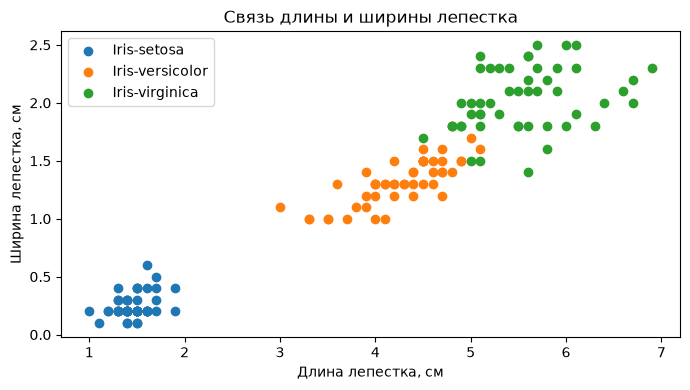

In [9]:
u = petal_length
v = petal_width

plt.figure(figsize=(7, 4))
for name in np.unique(species):
    mask = species == name
    plt.scatter(u[mask], v[mask], label=name)
plt.xlabel('Длина лепестка, см')
plt.ylabel('Ширина лепестка, см')
plt.title('Связь длины и ширины лепестка')
plt.legend()
plt.tight_layout()
plt.show()

### Перестановочный тест с коэффициентом Пирсона

$H_0$: длина и ширина лепестка независимы.

$H_1$: между признаками есть зависимость. Используемая статистика чувствительна прежде всего к линейной связи.

Самостоятельно считаем коэффициент корреляции:

$$r = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum (x_i - \bar x)^2 \sum (y_i - \bar y)^2}}.$$

Для p-value перемешиваем ширины относительно длин и снова считаем коэффициент. При $H_0$ это не меняет совместное распределение. Сравниваем модули коэффициентов, поскольку проверка двусторонняя. Нормальность для такого теста не требуется.

In [10]:
def pearson_r(x, y):
    dx = x - x.mean()
    dy = y - y.mean()
    return np.sum(dx * dy) / np.sqrt(np.sum(dx ** 2) * np.sum(dy ** 2))

r = pearson_r(u, v)
count = 0
for _ in range(R):
    r_sim = pearson_r(u, rng.permutation(v))
    if abs(r_sim) >= abs(r):
        count += 1
p_corr = (count + 1) / (R + 1)

print(f'r = {r:.4f}, p = {p_corr:.4f}')
print('Отклоняем H0:', p_corr < alpha)

r = 0.9629, p = 0.0002
Отклоняем H0: True


### Критерий Спирмена

$H_0$: ранговая корреляция равна нулю, $\rho_s = 0$.

$H_1$: ранговая корреляция не равна нулю, $\rho_s \ne 0$.

Критерий Спирмена оценивает монотонную связь по рангам. Используем библиотечную реализацию с приближённым асимптотическим p-value. Нулевая корреляция сама по себе не означает независимость.

In [11]:
rho, p_spearman = spearmanr(u, v, alternative='two-sided')
print(f'rho = {rho:.4f}, p = {p_spearman:.6g}')
print('Отклоняем H0:', p_spearman < alpha)

rho = 0.9377, p = 8.1566e-70
Отклоняем H0: True


### Вывод

Оба критерия обнаружили связь длины и ширины лепестка. Коэффициент Пирсона примерно равен 0.963, Спирмена — 0.938. Связь сильная и положительная.

Это результат по всем видам вместе. Часть связи объясняется различиями между видами, что видно на графике. Такой результат не доказывает ту же силу связи внутри каждого вида и не означает причинность.

## Результаты

В каждом задании использованы два разных критерия, один из которых реализован самостоятельно. Соберём полученные p-value и решения.

In [12]:
names = ['Шапиро — Уилка', 'Пирсона (свой)',
         'Колмогорова — Смирнова (свой)', 'Крамера — фон Мизеса',
         'Пирсон: перестановки (свой)', 'Спирмен']
p_values = [p_shapiro, p_pearson, p_ks, p_cvm, p_corr, p_spearman]

print('Критерий                         p-value    Отклоняем H0')
for name, p in zip(names, p_values):
    print(f'{name:32s} {p:10.4g}    {p < alpha}')

Критерий                         p-value    Отклоняем H0
Шапиро — Уилка                       0.1012    False
Пирсона (свой)                       0.0966    False
Колмогорова — Смирнова (свой)        0.0002    True
Крамера — фон Мизеса               7.05e-12    True
Пирсон: перестановки (свой)          0.0002    True
Спирмен                           8.157e-70    True


Минимальное p-value при $R=4999$ повторениях равно $1/5000 = 0.0002$. Это ограничение точности моделирования, а не точное значение вероятности. Два критерия на одних данных не являются независимыми подтверждениями результата.